# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RamyaMuthumariappan/FlyRankAI/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

**Lane:** Lane 2 — Refresh / Content Opportunity Scoring.

Weeks 4–6 produced a transparent rule (W4), a Random Forest (W5), and an audit that told me how far to trust the model (W6). This notebook turns that into something a person can *use*: a ranked queue with reason codes, a page-type → action map, human-review rules, a no-go list, and monitoring triggers. It is **decision-support for a human editor, not an automated refresh system**, and everything is written in observed / measured / directional language.

**What the W6 audit means for this playbook (carried forward on purpose):**
- The W5 label is a *proxy* built from a rule; no editor-confirmed outcome exists yet.
- The model's strongest inputs are ingredients of that proxy, so its score is a **second opinion**, not the reason a page is recommended. Reason codes come from visible, checkable columns.
- Nothing here measures whether a refresh *pays off*. The data is one snapshot with no intervention.

**Data:** the starter dataset (`data/raw/content_refresh_anonymized.csv`, 30,000 rows / 32 clients), the same rows W4–W6 used. IDs are pseudonyms and are used only for grouping and for naming rows in the queue file.

In [1]:
import os, sys, subprocess, json, warnings
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/RamyaMuthumariappan/FlyRankAI.git"
REPO_DIR = "FlyRankAI"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    while not os.path.isdir("data/raw") and os.getcwd() != "/":
        os.chdir("..")

assert os.path.exists("data/raw/content_refresh_anonymized.csv"), "starter CSV not found - are you at the repo root?"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

SEED = 42
OUT_DIR, FIG_DIR = "work/outputs", "work/figures"
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

RECEIPTS = {"seed": SEED, "sklearn_version": sklearn.__version__}   # every headline number lands here -> work/outputs/w07_playbook_metrics.json
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
print("Working dir:", os.getcwd())
print("Rows, columns:", df.shape, "| distinct clients:", df["client_id"].nunique(), "| seed:", SEED, "| scikit-learn:", sklearn.__version__)

# ---- plain chart style (one message per chart, recessive grid, direct labels) ----
INK, MUTED, GRID = "#1f2937", "#6b7280", "#e5e7eb"
C_MAIN, C_ALT, C_WARN = "#2a6fb0", "#9aa3af", "#c4572b"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})

Working dir: /content/FlyRankAI
Rows, columns: (30000, 44) | distinct clients: 32 | seed: 42 | scikit-learn: 1.6.1


## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

### 1a. How the queue is built (and what each number is allowed to mean)

Three ingredients, each with a different job:

| Ingredient | Where it comes from | Its job in the queue |
|---|---|---|
| **Reason codes** (`low_ctr_visible_page`, `stale_visible_page`, …) | The W4 rule thresholds on visible columns: `impressions_last_30d`, `avg_position`, `ctr`, `days_since_last_update` | *Why* a page is on the list. A human can re-check each one in Search Console. |
| **Value, by lane** | CTR-gap pages: the *recoverable-clicks ceiling* (`click_gap_90d`, defined in 1e). Stale-only pages: `impressions_last_30d` (visibility at stake) | **Orders** the queue. Each lane is ranked by its own value measure, then the two lanes are merged by within-lane percentile (best of each lane first, in proportion to lane size). |
| **Model second opinion** (`model_oof_prob`) | The W5 Random Forest, scored **out-of-fold by client** (`GroupKFold(5)`, so no page is scored by a model that saw its client) | Feeds the **confidence label** and a `model_disagrees` flag. It does **not** set the order: W6 showed its score largely re-reads the rule that defines the proxy. It is **not** a probability that a refresh will work. |

`priority_score = 100 × within-lane percentile of the lane's value measure`, computed only among pages with an action (refresh family). Section 1e shows how much the top of the list would change if the model were given a say.

Banned from every input here: `trend_direction`, `trend_pct`, `is_declining_label` (they define the proxy label). The decline proxy is carried in the export only as a labelled *context* column for later evaluation.

In [2]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# ---- the W2/W5 proxy label: rebuilt EXACTLY, used for EVALUATION ONLY ----
df["is_declining_label"] = (df["trend_direction"] == "down").astype(int)
page1_decay = (df["avg_position"] > 0) & (df["avg_position"] <= 10) & (df["is_declining_label"] == 1)
stale_visible_label = (df["days_since_last_update"] > 60) & (df["impressions_last_30d"] > 50)
df["y_high"] = (page1_decay | stale_visible_label).astype(int)
y, groups = df["y_high"].values, df["client_id"].values
print(f"Proxy 'high-priority' base rate: {y.mean():.3f}  (n={len(df):,})  <- every score below must be read against this")

# ---- W5 feature set, EXACT (same fills, same leakage guard) ----
for c_out, c_in in [("log_impressions_90d","impressions_90d"),("log_clicks_90d","clicks_90d"),
                    ("log_sessions_90d","sessions_90d"),("log_ai_sessions_90d","ai_sessions_90d")]:
    df[c_out] = np.log1p(df[c_in])
df["has_word_count"] = df["word_count"].notna().astype(int)
df["has_keyword_data"] = df["search_volume"].notna().astype(int)
NUM = ["search_volume","competition","cpc","word_count","char_count","log_impressions_90d","log_clicks_90d",
       "log_sessions_90d","log_ai_sessions_90d","days_with_impressions","days_with_sessions","content_age_days",
       "days_since_last_update","ctr","avg_position","engagement_rate","scroll_rate","ai_traffic_pct",
       "has_word_count","has_keyword_data"]
CAT = ["competition_level","content_type","main_intent","age_tier","freshness_tier","word_count_tier",
       "impression_tier","position_tier"]
X = df[NUM + CAT].copy()
for c in NUM: X[c] = X[c].fillna(0)
for c in CAT: X[c] = X[c].fillna("unknown").astype(str)
BANNED = {"trend_direction","trend_pct","is_declining_label","priority_tier","y_high"}
assert BANNED.isdisjoint(NUM + CAT), "banned label column in the feature list - stop."
print(f"Leakage guard passed: {len(NUM)} numeric + {len(CAT)} categorical features, no banned column present.")

def make_model(nums, cats):
    pre = ColumnTransformer([("num", StandardScaler(), nums), ("cat", OneHotEncoder(handle_unknown="ignore"), cats)])
    rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
    return Pipeline([("pre", pre), ("clf", rf)])

def oof_scores(nums, cats):
    """Client-grouped 5-fold, out-of-fold: every page is scored by a model that never saw its client."""
    oof, aucs = np.zeros(len(X)), []
    for tr, te in GroupKFold(n_splits=5).split(X, y, groups):
        m = make_model(nums, cats).fit(X.iloc[tr][nums + cats], y[tr])
        oof[te] = m.predict_proba(X.iloc[te][nums + cats])[:, 1]
        aucs.append(roc_auc_score(y[te], oof[te]))
    return oof, np.array(aucs)

oof_prob, aucs_A = oof_scores(NUM, CAT)

# the W6 ablation, recomputed live: drop the 4 columns that are ingredients of the proxy label
ING_N, ING_C = ["avg_position", "days_since_last_update"], ["position_tier", "freshness_tier"]
oof_noing, aucs_B = oof_scores([c for c in NUM if c not in ING_N], [c for c in CAT if c not in ING_C])

print(f"\nGrouped 5-fold OOF AUC  A (W5 features as-is):            mean {aucs_A.mean():.3f}  sd {aucs_A.std():.3f}  worst fold {aucs_A.min():.3f}")
print(f"Grouped 5-fold OOF AUC  B (minus 4 label-ingredient cols): mean {aucs_B.mean():.3f}  sd {aucs_B.std():.3f}  worst fold {aucs_B.min():.3f}")
print("W6 reported A = 0.946 and B = 0.658 (Colab, scikit-learn 1.6.1). A match within ~0.01 means this notebook reproduces the W6 story;")
print("fold assignment can differ slightly across scikit-learn versions, so I report THIS run's numbers below.")

# per-client reliability: OOF AUC where the client has enough rows and both classes
client_auc, client_n = {}, df.groupby("client_id").size()
for cid, idx in df.groupby("client_id").indices.items():
    if len(idx) >= 200 and 0 < y[idx].sum() < len(idx):
        client_auc[cid] = roc_auc_score(y[idx], oof_prob[idx])
ca = pd.Series(client_auc)
print(f"\nClients with >=200 rows and both classes: {len(ca)} of {df['client_id'].nunique()}  |  per-client OOF AUC: min {ca.min():.2f}, median {ca.median():.2f}, max {ca.max():.2f}")
print(f"Clients below 0.80: {(ca < 0.80).sum()}   |  clients with <200 rows (model unverifiable): {(client_n < 200).sum()}")
RECEIPTS["model_check"] = {
    "oof_auc_A_mean": round(float(aucs_A.mean()), 3), "oof_auc_A_sd": round(float(aucs_A.std()), 3), "oof_auc_A_worst_fold": round(float(aucs_A.min()), 3),
    "oof_auc_B_minus_ingredients_mean": round(float(aucs_B.mean()), 3), "oof_auc_B_worst_fold": round(float(aucs_B.min()), 3),
    "proxy_base_rate": round(float(y.mean()), 3), "n_rows": int(len(df)), "n_clients": int(df["client_id"].nunique()),
    "clients_scored_ge200_rows": int(len(ca)), "clients_auc_below_0.80": int((ca < 0.80).sum()),
    "client_auc_min": round(float(ca.min()), 3), "client_auc_median": round(float(ca.median()), 3), "client_auc_max": round(float(ca.max()), 3),
    "w6_reference": {"A": 0.946, "B": 0.658}}


Proxy 'high-priority' base rate: 0.423  (n=30,000)  <- every score below must be read against this
Leakage guard passed: 20 numeric + 8 categorical features, no banned column present.

Grouped 5-fold OOF AUC  A (W5 features as-is):            mean 0.946  sd 0.023  worst fold 0.915
Grouped 5-fold OOF AUC  B (minus 4 label-ingredient cols): mean 0.658  sd 0.059  worst fold 0.567
W6 reported A = 0.946 and B = 0.658 (Colab, scikit-learn 1.6.1). A match within ~0.01 means this notebook reproduces the W6 story;
fold assignment can differ slightly across scikit-learn versions, so I report THIS run's numbers below.

Clients with >=200 rows and both classes: 21 of 32  |  per-client OOF AUC: min 0.66, median 0.93, max 0.99
Clients below 0.80: 2   |  clients with <200 rows (model unverifiable): 10


### 1b. Page types (archetypes) → action, reason codes, and the queue

**A naming caution.** These are *rule-based page types*, not clusters. Lane 2 does not cluster pages, and nothing here is "semantic" — the data has no article text. Each page gets exactly **one primary page type** (first match wins), plus any number of reason codes.

| Priority | Page type | Rule (visible = `impressions_last_30d ≥ 50`) | Suggested action |
|---|---|---|---|
| 1 | **Visible CTR gap** | visible, `0 < avg_position ≤ 20`, `ctr < 0.35` | `refresh_and_review_ctr` |
| 2 | **Stale but visible** | visible, `days_since_last_update ≥ 90` (and not type 1) | `refresh` |
| 3 | **Position unknown** | visible, `avg_position == 0` (no data), fresh | `data_check` |
| 4 | **Page-1 performer** | visible, `0 < avg_position ≤ 10`, `ctr ≥ 0.35`, updated < 90 days ago | `protect` |
| 5 | **Striking distance, healthy CTR** | visible, `10 < avg_position ≤ 20`, `ctr ≥ 0.35`, fresh | `expand_candidate` |
| 6 | **Visible but deep** | visible, `avg_position > 20`, fresh | `monitor` |
| 7 | **Prune-review candidate** | not visible, no impressions in last 30d, `< 10` impressions in 90d, age ≥ 180 days | `prune_review` *(human decision only)* |
| 8 | **Low visibility** | everything else (not visible) | `monitor` |

Types 1–2 are exactly the W4 rule (so the W4 counts reappear). Only types 1–2 enter the ranked queue; the rest get an action label but no queue rank. `expand_candidate` and `protect` are *hypotheses about what a human may want to do*, not findings.

In [3]:
# ---------------- page types, actions, reason codes ----------------
visible = df["impressions_last_30d"] >= 50
pos = df["avg_position"]
pos_ok = pos > 0
ctr_gap = visible & pos_ok & (pos <= 20) & (df["ctr"] < 0.35)
stale = visible & (df["days_since_last_update"] >= 90)
fresh = df["days_since_last_update"] < 90

df["page_type"] = np.select(
    [ctr_gap, stale, visible & ~pos_ok & fresh, visible & pos_ok & (pos <= 10) & (df["ctr"] >= 0.35) & fresh,
     visible & pos_ok & (pos > 10) & (pos <= 20) & (df["ctr"] >= 0.35) & fresh, visible & pos_ok & (pos > 20) & fresh,
     (~visible) & (df["impressions_last_30d"] == 0) & (df["impressions_90d"] < 10) & (df["content_age_days"] >= 180)],
    ["visible_ctr_gap", "stale_but_visible", "position_unknown", "page1_performer", "striking_distance_ok_ctr", "visible_but_deep", "prune_review_candidate"],
    default="low_visibility")
ACTION_OF = {"visible_ctr_gap": "refresh_and_review_ctr", "stale_but_visible": "refresh", "position_unknown": "data_check",
             "page1_performer": "protect", "striking_distance_ok_ctr": "expand_candidate", "visible_but_deep": "monitor",
             "prune_review_candidate": "prune_review", "low_visibility": "monitor"}
PRIMARY_CODE = {"visible_ctr_gap": "low_ctr_visible_page", "stale_but_visible": "stale_visible_page", "position_unknown": "position_missing",
                "page1_performer": "page1_protect", "striking_distance_ok_ctr": "striking_distance_ok_ctr", "visible_but_deep": "visible_but_deep",
                "prune_review_candidate": "prune_review_candidate", "low_visibility": "low_visibility"}
df["action"] = df["page_type"].map(ACTION_OF)
df["primary_reason"] = df["page_type"].map(PRIMARY_CODE)
ACTIONABLE = ["refresh_and_review_ctr", "refresh"]
act = df["action"].isin(ACTIONABLE)

# W4 continuity check: types 1-2 must reproduce the W4 counts (8,780 CTR-gap / 3,928 stale-only)
print("Reproduces the W4 rule counts?  CTR-gap:", int((df.page_type == "visible_ctr_gap").sum()), "(W4: 8,780)  |  stale-only:", int((df.page_type == "stale_but_visible").sum()), "(W4: 3,928)")

# ---------------- value proxy: recoverable-clicks CEILING (not a forecast) ----------------
valid = df[pos_ok]
tier_ctr = (valid.groupby("position_tier")["clicks_90d"].sum() / valid.groupby("position_tier")["impressions_90d"].sum() * 100)
BENCH = tier_ctr.to_dict()    # weighted CTR (%) by position tier, valid positions only (the W4 signal-2 table)
print("Weighted CTR benchmark by position tier (%):", {k: round(v, 3) for k, v in BENCH.items()})
bench_row = df["position_tier"].map(BENCH).where(pos_ok, 0.0).fillna(0.0)
df["click_gap_90d"] = (df["impressions_90d"] * np.clip(bench_row - df["ctr"], 0, None) / 100).round(1)

# ---------------- model second opinion + priority score (refresh family only) ----------------
df["model_oof_prob"] = oof_prob.round(4)
# value measure per lane: CTR-gap -> recoverable-clicks ceiling; stale-only -> visibility at stake. Percentile WITHIN lane, then merge.
lane_value = df["click_gap_90d"].where(df["action"] == "refresh_and_review_ctr", df["impressions_last_30d"])
lane_pct = lane_value[act].groupby(df.loc[act, "action"]).rank(pct=True)
def priority(w_model=0.0):
    """w_model = 0 is the playbook ordering; >0 blends in the model percentile (used only for the sensitivity check in 1e)."""
    s = pd.Series(np.nan, index=df.index)
    m_pct = df.loc[act, "model_oof_prob"].rank(pct=True)
    s.loc[act] = 100 * ((1 - w_model) * lane_pct + w_model * m_pct)
    return s
df["priority_score"] = priority(0.0).round(3)

order = df[act].sort_values(["priority_score", "impressions_last_30d"], ascending=False).index
df["queue_rank"] = np.nan
df.loc[order, "queue_rank"] = np.arange(1, len(order) + 1)
# per-client views: work the queue client by client, or take a client-balanced first sitting
df["client_queue_rank"] = df.loc[act].groupby("client_id")["queue_rank"].rank(method="first")
bal = df.loc[act].sort_values(["client_queue_rank", "queue_rank"]).index
df["client_balanced_rank"] = np.nan
df.loc[bal, "client_balanced_rank"] = np.arange(1, len(bal) + 1)
TIER1, TIER2 = 50, 250          # review capacity ASSUMPTIONS (first sitting / next few sittings) - FlyRank should replace with real capacity
df["review_tier"] = np.select([df["queue_rank"] <= TIER1, df["queue_rank"] <= TIER2, df["queue_rank"].notna()],
                              ["1_review_now", "2_next", "3_backlog"], default="")

# ---------------- confidence = strength of EVIDENCE (rule signals + volume + model agreement), not a probability ----------------
rel = pd.Series("unverified (<200 rows)", index=df.index)
cl_auc = df["client_id"].map(client_auc)
rel[cl_auc >= 0.80] = "ok"; rel[cl_auc < 0.80] = "weak"
df["client_model_reliability"] = rel
two_signals = ctr_gap & stale                       # two independent visible reasons agree
df["confidence"] = np.where(~act, "n/a", "low")
df.loc[act & (df["model_oof_prob"] >= 0.5) & (df["impressions_last_30d"] >= 100), "confidence"] = "medium"
df.loc[act & two_signals & (df["model_oof_prob"] >= 0.5) & (df["impressions_last_30d"] >= 500) & (df["client_model_reliability"] == "ok"), "confidence"] = "high"

# ---------------- human-check flags ----------------
near = ((df["ctr"].between(0.30, 0.35)) | (pos.between(17, 20)) | (df["days_since_last_update"].between(90, 100)))
flag_defs = {
    "position_missing": ~pos_ok,
    "client_model_weak_or_unverified": df["client_model_reliability"] != "ok",
    "no_keyword_data": df["search_volume"].isna(),
    "model_disagrees": act & (df["model_oof_prob"] < 0.5),
    "near_threshold": act & near,
    "very_high_volume_check_anomaly": df["impressions_last_30d"] >= 50000,
}
flag_df = pd.DataFrame(flag_defs)
df["review_flags"] = flag_df.apply(lambda r: "|".join(c for c in flag_df.columns if r[c]), axis=1)
df["needs_extra_check"] = df["review_flags"] != ""

# ---------------- reason codes (all that apply) and plain-English text ----------------
codes = pd.DataFrame({
    "low_ctr_visible_page": ctr_gap, "stale_visible_page": stale, "position_missing": visible & ~pos_ok,
    "page1_protect": df["page_type"] == "page1_performer", "striking_distance_ok_ctr": df["page_type"] == "striking_distance_ok_ctr",
    "prune_review_candidate": df["page_type"] == "prune_review_candidate",
    "model_agrees": act & (df["model_oof_prob"] >= 0.5), "model_disagrees": act & (df["model_oof_prob"] < 0.5)})
df["reason_codes"] = codes.apply(lambda r: "|".join(c for c in codes.columns if r[c]), axis=1)
df.loc[df["reason_codes"] == "", "reason_codes"] = df["primary_reason"]

def reason_text(r):
    bits = []
    if r.page_type in ("visible_ctr_gap",):
        bits.append(f"ranks at position {r.avg_position:.1f} but CTR is {r.ctr:.2f}% (benchmark ~{BENCH.get(r.position_tier, 0.35):.2f}%) on {int(r.impressions_last_30d):,} impressions in 30 days")
        if r.days_since_last_update >= 90: bits.append(f"also not updated for {int(r.days_since_last_update)} days")
    elif r.page_type == "stale_but_visible":
        bits.append(f"not updated for {int(r.days_since_last_update)} days while still earning {int(r.impressions_last_30d):,} impressions in 30 days")
    elif r.page_type == "position_unknown": bits.append("visible, but no position data - cannot judge CTR; check Search Console before anything else")
    elif r.page_type == "page1_performer": bits.append(f"healthy page-1 page (position {r.avg_position:.1f}, CTR {r.ctr:.2f}%, updated {int(r.days_since_last_update)} days ago) - protect, do not churn")
    elif r.page_type == "striking_distance_ok_ctr": bits.append(f"position {r.avg_position:.1f} with healthy CTR - candidate for a human to consider expansion")
    elif r.page_type == "visible_but_deep": bits.append(f"visible but ranks deep (position {r.avg_position:.1f}); no action suggested beyond monitoring")
    elif r.page_type == "prune_review_candidate": bits.append(f"almost no search visibility (<10 impressions in 90 days) and {int(r.content_age_days)} days old - human review for merge/redirect/keep")
    else: bits.append("low recent visibility; monitor")
    if r.action in ACTIONABLE:
        bits.append("model second opinion " + ("agrees" if r.model_oof_prob >= 0.5 else "DISAGREES") + f" (score {r.model_oof_prob:.2f})")
    return "; ".join(bits)
df["reason_text"] = df.apply(reason_text, axis=1)

print("\nAction counts (all 30,000 rows):"); print(df["action"].value_counts().to_string())
print(f"\nRanked queue (refresh family): {int(act.sum()):,} pages = {act.mean():.1%} of the catalogue. Tier 1 = top {TIER1}, tier 2 = next {TIER2 - TIER1}, tier 3 = backlog.")
print("Confidence mix inside the queue:", df.loc[act, "confidence"].value_counts().to_dict())
print("Primary reason inside tier 1 + tier 2:", df.loc[df["queue_rank"] <= TIER2, "primary_reason"].value_counts().to_dict())
conc = {}
for k in (TIER1, TIER2, 1000):
    sub = df[df["queue_rank"] <= k]; top_share = sub["client_id"].value_counts(normalize=True)
    conc[k] = {"largest_client_share": round(float(top_share.iloc[0]), 3), "clients_present": int(sub["client_id"].nunique())}
print("Client concentration of the top of the queue (largest single client's share, clients present):", conc)
RECEIPTS["queue_client_concentration"] = conc
print(f"Rows in the queue needing at least one extra human check: {df.loc[act, 'needs_extra_check'].mean():.1%}")

Reproduces the W4 rule counts?  CTR-gap: 8780 (W4: 8,780)  |  stale-only: 3928 (W4: 3,928)
Weighted CTR benchmark by position tier (%): {'deep': 0.041, 'page_1': 0.35, 'page_3_5': 0.155, 'striking': 0.347, 'top_3': 0.489}

Action counts (all 30,000 rows):
action
monitor                   13783
refresh_and_review_ctr     8780
refresh                    3928
protect                    1961
prune_review                820
expand_candidate            728

Ranked queue (refresh family): 12,708 pages = 42.4% of the catalogue. Tier 1 = top 50, tier 2 = next 200, tier 3 = backlog.
Confidence mix inside the queue: {'medium': 6946, 'low': 4242, 'high': 1520}
Primary reason inside tier 1 + tier 2: {'low_ctr_visible_page': 173, 'stale_visible_page': 77}
Client concentration of the top of the queue (largest single client's share, clients present): {50: {'largest_client_share': 0.5, 'clients_present': 7}, 250: {'largest_client_share': 0.516, 'clients_present': 14}, 1000: {'largest_client_share': 0.4

In [4]:
# ---------------- the top of the queue, read the way an editor would (no IDs printed; the full queue is exported in section 5) ----------------
top = df[act].sort_values("queue_rank").head(15)
show = top[["queue_rank", "action", "avg_position", "ctr", "impressions_last_30d", "days_since_last_update", "click_gap_90d", "model_oof_prob", "confidence", "review_flags"]].copy()
show["queue_rank"] = show["queue_rank"].astype(int)
show["review_flags"] = show["review_flags"].replace("", "-")
print(show.to_string(index=False))
print("\nPlain-English reason for ranks 1-3:")
for _, r in top.head(3).iterrows():
    print(f"  #{int(r.queue_rank)}: {r.reason_text}")
print("\nWhat would make a pick wrong: for CTR-gap pages, the low CTR may be structural (an answer box or AI overview absorbing clicks) or the")
print("intent may not want a click; for stale pages, the last update may have been a bulk/template change rather than an editor looking at the page.")

 queue_rank                 action  avg_position  ctr  impressions_last_30d  days_since_last_update  click_gap_90d  model_oof_prob confidence                                   review_flags
          1                refresh          27.9 0.21                139891                     104            0.0          0.9172     medium                 very_high_volume_check_anomaly
          2 refresh_and_review_ctr           2.5 0.15                 89463                      20         1724.0          0.3857        low model_disagrees|very_high_volume_check_anomaly
          3 refresh_and_review_ctr           2.3 0.03                168958                      20         1247.9          0.4138        low model_disagrees|very_high_volume_check_anomaly
          4 refresh_and_review_ctr           4.2 0.14                120791                     104         1088.9          0.9157       high                 very_high_volume_check_anomaly
          5                refresh           2.0 0.87  

### 1c. Page type → action map, with the evidence behind each row

The table puts each page type next to what the data *observed* about it. The **decline-proxy rate** and **proxy-high rate** are post-hoc context only (the decline proxy never enters the scoring), and neither says a refresh would help. The last two columns are the human part: who decides, and what must be checked first.

In [5]:
HUMAN_DECISION = {
    "visible_ctr_gap": ("Editor proposes new title/meta and checks content; strategist approves", "SERP check: is an answer box / AI overview absorbing clicks? Does the query intent want a click?"),
    "stale_but_visible": ("Editor decides refresh scope", "Is the information actually outdated? Is the page still the right target for its keyword?"),
    "position_unknown": ("Analyst", "Pull position from Search Console; re-type the page once data exists"),
    "page1_performer": ("Editor (leave alone unless asked)", "Avoid churn on a page that works; confirm no recent drop in Search Console"),
    "striking_distance_ok_ctr": ("Strategist", "Treat as a hypothesis: is there a content gap worth adding? No evidence here that expansion helps"),
    "visible_but_deep": ("None", "Re-check next cycle"),
    "prune_review_candidate": ("Strategist + second reviewer (never automated)", "Is it linked, redirected, seasonal, or new-in-index? Merge/redirect/keep is a human call"),
    "low_visibility": ("None", "Re-check next cycle")}
rows = []
for pt, g in df.groupby("page_type"):
    rows.append({"page_type": pt, "action": ACTION_OF[pt], "n": len(g), "share": round(len(g) / len(df), 3),
                 "median_impr_30d": float(g["impressions_last_30d"].median()),
                 "decline_proxy_rate": round(float(g["is_declining_label"].mean()), 3),
                 "proxy_high_rate": round(float(g["y_high"].mean()), 3)})
amap = pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)
amap["who_decides"] = amap["page_type"].map(lambda p: HUMAN_DECISION[p][0])
amap["check_first"] = amap["page_type"].map(lambda p: HUMAN_DECISION[p][1])
print(f"Overall decline-proxy rate {df['is_declining_label'].mean():.3f} | overall proxy-high rate {y.mean():.3f}\n")
print(amap[["page_type", "action", "n", "share", "median_impr_30d", "decline_proxy_rate", "proxy_high_rate"]].to_string(index=False))
print("\nHuman side of the map:")
print(amap[["page_type", "who_decides", "check_first"]].to_string(index=False))
RECEIPTS["archetype_action_map"] = amap.to_dict(orient="records")
print("\nCaution on proxy_high_rate: the proxy label is built from the SAME columns as these page types (position, staleness, visibility), so values near 0 or 1")
print("(e.g. stale_but_visible, striking_distance, visible_but_deep) hold by construction. They are NOT validation of the page types.")
sv_rate = float(amap.set_index("page_type").loc["stale_but_visible", "decline_proxy_rate"]); gap_rate = float(amap.set_index("page_type").loc["visible_ctr_gap", "decline_proxy_rate"])
print(f"The decline proxy is the only column here not built from the rule: CTR-gap pages {gap_rate:.3f}, stale-but-visible pages {sv_rate:.3f}, whole catalogue {df['is_declining_label'].mean():.3f}.")
print("-> stale-but-visible pages do NOT show a higher decline-proxy rate than the catalogue; the CTR-gap family does. Staleness is the weaker reason.")
small = amap[amap["n"] < 1000]["page_type"].tolist()
print(f"\nNote: page types with n < 1,000 ({small}) are small - read their rates as directional only.")

Overall decline-proxy rate 0.542 | overall proxy-high rate 0.423

               page_type                 action     n  share  median_impr_30d  decline_proxy_rate  proxy_high_rate
          low_visibility                monitor 10507  0.350              4.0               0.542            0.253
         visible_ctr_gap refresh_and_review_ctr  8780  0.293            498.0               0.614            0.575
       stale_but_visible                refresh  3928  0.131            713.0               0.527            0.997
        visible_but_deep                monitor  3276  0.109            259.5               0.463            0.000
         page1_performer                protect  1961  0.065           1053.0               0.465            0.465
  prune_review_candidate           prune_review   820  0.027              0.0               0.352            0.189
striking_distance_ok_ctr       expand_candidate   728  0.024            439.5               0.532            0.000

Human side of

### 1d. The decay / refresh insight

**Question:** do pages that have gone longer without an update show more decline? And what does the data let me say about *refreshing*?

I look at the **decline proxy** (last-30-day impressions more than 20% below the prior 30 days) against `days_since_last_update`, with the sample size and a 95% interval on every bucket. This is a snapshot of different pages, **not** the same pages before and after a refresh, so it can describe a pattern; it cannot say that a refresh helps. Who got refreshed, and when, was also a choice someone made, so part of any gap may be that choice rather than the refresh.

Decline-proxy rate by freshness tier - ALL pages:
bucket     n  decline_rate  ci95_low  ci95_high  median_impr_30d
  0-30 20480         0.511     0.505      0.518             86.0
 31-90   175         0.589     0.515      0.659             67.0
91-180  9171         0.611     0.601      0.621            305.0
  181+   174         0.471     0.399      0.545              4.0

Same, VISIBLE pages only (impressions_last_30d >= 50) - removes near-zero-traffic noise:
bucket     n  decline_rate  ci95_low  ci95_high  median_impr_30d
  0-30 11499         0.533     0.524      0.542            442.0
 31-90    99         0.424     0.332      0.523            181.0
91-180  7047         0.580     0.569      0.592            597.0
  181+    28         0.643     0.458      0.793            162.0

Finer buckets (visible pages) - note how thin the middle is:
 bucket    n  decline_rate  ci95_low  ci95_high  median_impr_30d
   0-14 2027         0.584     0.562      0.605            388.0
  15-30 9472      

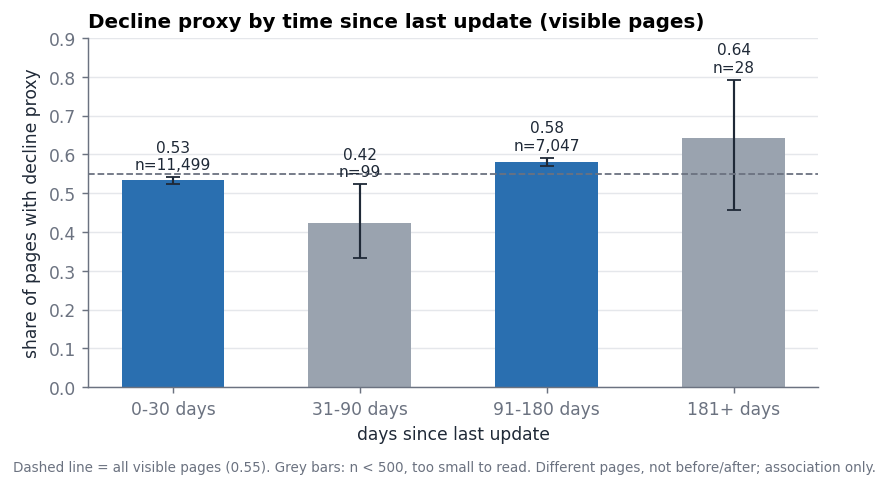

In [6]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

def decay_table(frame, by, labels=None):
    rows = []
    for key, g in frame.groupby(by, observed=True):
        lo, hi = wilson(int(g["is_declining_label"].sum()), len(g))
        rows.append({"bucket": key, "n": len(g), "decline_rate": round(g["is_declining_label"].mean(), 3),
                     "ci95_low": round(lo, 3), "ci95_high": round(hi, 3), "median_impr_30d": float(g["impressions_last_30d"].median())})
    return pd.DataFrame(rows)

tier_order = ["0-30", "31-90", "91-180", "181+"]
df["freshness_tier"] = pd.Categorical(df["freshness_tier"], categories=tier_order, ordered=True)
t_all = decay_table(df, "freshness_tier")
t_vis = decay_table(df[visible], "freshness_tier")
print("Decline-proxy rate by freshness tier - ALL pages:"); print(t_all.to_string(index=False))
print("\nSame, VISIBLE pages only (impressions_last_30d >= 50) - removes near-zero-traffic noise:"); print(t_vis.to_string(index=False))

# finer cut: how is update timing actually distributed?
bins = [-1, 14, 30, 60, 90, 120, 180, 10_000]
labels = ["0-14", "15-30", "31-60", "61-90", "91-120", "121-180", "181+"]
df["days_bucket"] = pd.cut(df["days_since_last_update"], bins=bins, labels=labels)
t_fine = decay_table(df[visible], "days_bucket")
print("\nFiner buckets (visible pages) - note how thin the middle is:"); print(t_fine.to_string(index=False))

# robustness: does the 91-180 vs 0-30 gap point the same way inside individual clients?
cl = []
for cid, g in df[visible].groupby("client_id"):
    a, b = g[g["freshness_tier"] == "0-30"], g[g["freshness_tier"] == "91-180"]
    if len(a) >= 50 and len(b) >= 50:
        cl.append(b["is_declining_label"].mean() - a["is_declining_label"].mean())
cl = np.array(cl)
print(f"\nWithin-client check (visible pages, clients with >=50 pages in BOTH tiers): {len(cl)} clients; "
      f"91-180 has the higher decline rate in {(cl > 0).sum()} of {len(cl)}; median gap {np.median(cl):+.3f}")

# update timing is clustered: how many pages share the same days_since_last_update, and which clients?
vc = df["days_since_last_update"].value_counts()
top2 = vc.head(2)
cl104 = df[df["days_since_last_update"] == vc.index[1]]["client_id"].value_counts()
print(f"\nUpdate timing is clustered: the two most common values ({int(top2.index[0])} and {int(top2.index[1])} days) cover {top2.sum() / len(df):.0%} of all pages;")
print(f"{int(top2.iloc[1]):,} pages share exactly {int(top2.index[1])} days, and 3 clients account for {cl104.head(3).sum() / cl104.sum():.0%} of them -> these look like bulk updates, not page-by-page edits.")
agg_gap = float(t_vis.set_index("bucket").loc["91-180", "decline_rate"] - t_vis.set_index("bucket").loc["0-30", "decline_rate"])
all_gap = float(t_all.set_index("bucket").loc["91-180", "decline_rate"] - t_all.set_index("bucket").loc["0-30", "decline_rate"])
print(f"Gap in decline-proxy rate, 91-180 minus 0-30 days: {all_gap:+.3f} across ALL pages, {agg_gap:+.3f} across VISIBLE pages (about half of the W4 all-page gap goes away once near-zero-traffic pages are removed).")
RECEIPTS["update_timing_clustering"] = {"top2_share_of_pages": round(float(top2.sum() / len(df)), 3), "top2_values_days": [int(i) for i in top2.index],
                                        "gap_91_180_minus_0_30_all": round(all_gap, 3), "gap_visible": round(agg_gap, 3)}
g1 = t_vis.set_index("bucket")
RECEIPTS["decay_insight"] = {
    "all_pages": t_all.to_dict(orient="records"), "visible_pages": t_vis.to_dict(orient="records"), "fine_buckets_visible": t_fine.to_dict(orient="records"),
    "within_client_clients": int(len(cl)), "within_client_91_180_higher": int((cl > 0).sum()), "within_client_median_gap": round(float(np.median(cl)), 3),
    "wording": "observed association in one snapshot; selection into 'refreshed' is not controlled; no causal claim"}

# ---- figure 2 ----
fig, ax = plt.subplots(figsize=(6.4, 3.6))
xs = np.arange(len(t_vis)); r = t_vis["decline_rate"].values
ax.bar(xs, r, color=[C_MAIN, C_ALT, C_MAIN, C_ALT], width=0.55)
ax.errorbar(xs, r, yerr=[r - t_vis["ci95_low"].values, t_vis["ci95_high"].values - r], fmt="none", ecolor=INK, capsize=4, lw=1.2)
for x, (rate, n) in enumerate(zip(r, t_vis["n"])):
    ax.text(x, t_vis["ci95_high"].values[x] + 0.012, f"{rate:.2f}\nn={n:,}", ha="center", va="bottom", fontsize=8.5, color=INK)
ax.axhline(df.loc[visible, "is_declining_label"].mean(), color=MUTED, ls="--", lw=1)
ax.set_xticks(xs); ax.set_xticklabels([f"{b} days" for b in t_vis["bucket"]]); ax.set_ylim(0, 0.9)
ax.set_ylabel("share of pages with decline proxy"); ax.set_xlabel("days since last update")
ax.set_title("Decline proxy by time since last update (visible pages)")  # one message: modest gap, tiny middle buckets
ax.grid(axis="x", visible=False)
fig.text(0.01, -0.02, f"Dashed line = all visible pages ({df.loc[visible, 'is_declining_label'].mean():.2f}). Grey bars: n < 500, too small to read. Different pages, not before/after; association only.", fontsize=7.5, color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/w07_fig_decay_by_freshness.png", bbox_inches="tight"); plt.show()

**What I will say about decay / refresh (observed, directional, and deliberately modest):**
- In aggregate, visible pages last updated 91–180 days ago show a **somewhat higher** decline-proxy rate than visible pages updated within 30 days (the intervals do not overlap). The gap is **about half** the all-page gap W4 reported, so part of that earlier gap came from near-zero-traffic pages.
- It is **not a dose-response**: the *most* recently updated pages (0–14 days) show a higher rate than 15–30 days, which is what you would get if pages are often updated *because* they are already falling. That is the selection problem in the data, visible in a single table.
- **Update timing is clustered.** A large share of pages share just two `days_since_last_update` values, and one of them (104 days) comes mostly from a few clients. So "stale" here often means "this client's last bulk update", and the 31–90 day middle is nearly empty. I cannot place a "decay window" in days.
- **Inside individual clients the direction is not consistent**: only a handful of clients have enough pages in both buckets, and the 91–180 bucket is higher in some but not all of them. The aggregate gap is partly a between-client difference.
- **Staleness is the weaker reason code.** Stale-but-visible pages do not show a higher decline-proxy rate than the catalogue (section 1c); the CTR-gap family does. That matches W4's MIXED verdict on staleness, and it is why `stale_visible_page` is a *review reason* for a human, not a prediction.

**What I will not say:** that refreshing pages reverses decline, or how many days a page can wait. That needs the same pages before and after, with some pages left alone for comparison.

### 1e. Cost / value thinking

Two things are cheap to state and easy to over-state, so I keep them separate:

- **Value:** a *recoverable-clicks ceiling* per page = `impressions_90d × (benchmark CTR for its position tier − its CTR) / 100`, floored at 0. It is the clicks a page would have gained **if it matched the typical CTR at its position**, an upper bound, not a forecast, and only defined where a position exists. It says nothing about staleness value.
- **Cost:** editor-hours per action. **These are illustrative assumptions (not measured)**; FlyRank should replace them with real figures. The point is the *shape* of the trade-off, not the exact hours.

Total recoverable-clicks CEILING across the 12,708-page queue: 151,433 clicks per 90 days (upper bound, not a forecast)

 pages_reviewed  assumed_editor_hours  ceiling_clicks_90d  share_of_total_ceiling  ceiling_clicks_per_editor_hour  best_case_share_if_ordered_by_gap
             50                 184.0               18593                   0.123                           101.0                              0.145
            250                 923.0               44279                   0.292                            48.0                              0.339
           1000                3691.0               83054                   0.548                            22.5                              0.604
          12708               46904.0              151433                   1.000                             3.2                              1.000

Illustrative scenario (assumption, not an estimate): if only a fraction of the gap were closed for the first 250 pages
    10% of the

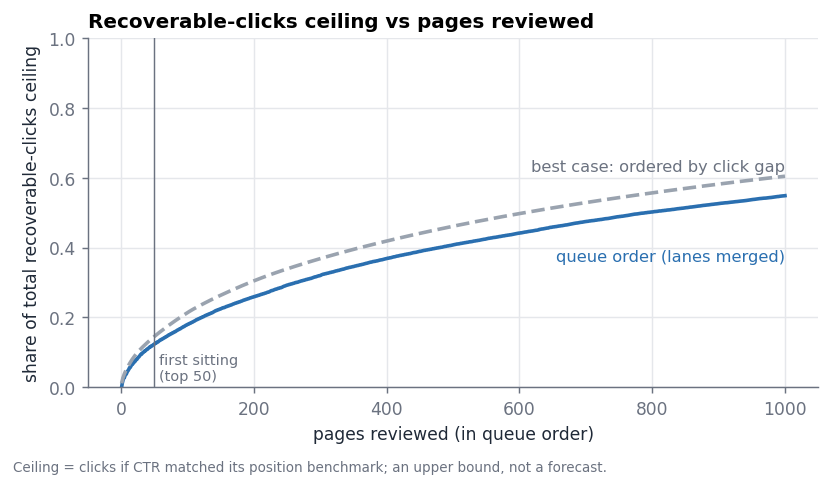

In [7]:
EFFORT_H = {"refresh_and_review_ctr": 4.0, "refresh": 3.0, "data_check": 0.25, "protect": 0.0, "expand_candidate": 0.5,
            "monitor": 0.0, "prune_review": 0.5}   # ASSUMPTIONS, hours per page
df["effort_hours_assumed"] = df["action"].map(EFFORT_H)

q = df[act].sort_values("queue_rank")
total_gap = q["click_gap_90d"].sum()
best = q.sort_values("click_gap_90d", ascending=False)
rows = []
for k in [50, 250, 1000, len(q)]:
    sel = q.head(k); sel_best = best.head(k)
    rows.append({"pages_reviewed": k, "assumed_editor_hours": float(sel["effort_hours_assumed"].sum()),
                 "ceiling_clicks_90d": int(sel["click_gap_90d"].sum()), "share_of_total_ceiling": round(sel["click_gap_90d"].sum() / total_gap, 3),
                 "ceiling_clicks_per_editor_hour": round(sel["click_gap_90d"].sum() / max(sel["effort_hours_assumed"].sum(), 1e-9), 1),
                 "best_case_share_if_ordered_by_gap": round(sel_best["click_gap_90d"].sum() / total_gap, 3)})
cv = pd.DataFrame(rows)
print(f"Total recoverable-clicks CEILING across the {len(q):,}-page queue: {int(total_gap):,} clicks per 90 days (upper bound, not a forecast)\n")
print(cv.to_string(index=False))
print("\nIllustrative scenario (assumption, not an estimate): if only a fraction of the gap were closed for the first 250 pages")
for cap in (0.10, 0.25, 0.50):
    print(f"   {cap:>4.0%} of the gap closed -> ~{int(q.head(250)['click_gap_90d'].sum() * cap):,} extra clicks per 90 days")
rho_gap = spearmanr(q["priority_score"], q["click_gap_90d"])[0]
rho_lane = spearmanr(q.loc[q["action"] == "refresh_and_review_ctr", "priority_score"], q.loc[q["action"] == "refresh_and_review_ctr", "click_gap_90d"])[0]
print(f"\nSpearman(priority_score, click gap): whole queue {rho_gap:+.2f}; inside the CTR-gap lane {rho_lane:+.2f}")

# how much does the top of the queue move if the model were given a say? (w = weight on the model percentile; w = 0 is the playbook ordering)
base_top = set(df.loc[df["queue_rank"] <= 100].index)
sens = {}
for w in [0.0, 0.25, 0.5, 1.0]:
    s = priority(w); top_w = set(s.sort_values(ascending=False).head(100).index)
    sens[str(w)] = len(base_top & top_w)
print("\nTop-100 overlap with the playbook ordering, by weight given to the model percentile:", sens)
print("(the model score saturates near 1 for many pages because the proxy label is built from the same columns, so it separates the very top poorly)")
capt = {k: round(float(q.head(k)['click_gap_90d'].sum() / total_gap), 3) for k in (50, 250, 1000)}
bestc = {k: round(float(best.head(k)['click_gap_90d'].sum() / total_gap), 3) for k in (50, 250, 1000)}
print(f"Share of the ceiling captured by the first 50/250/1000 pages: queue order {capt} vs best case (ordered by gap alone) {bestc}")

RECEIPTS["cost_value"] = {"total_gap_ceiling_90d": int(total_gap), "table": cv.to_dict(orient="records"), "effort_hours_ASSUMPTIONS": EFFORT_H,
                          "rank_corr_priority_vs_gap": round(float(rho_gap), 3), "top100_overlap_by_model_weight": sens,
                          "note": "ceiling = clicks if CTR matched the position-tier benchmark; upper bound, not a forecast; hours are illustrative"}

# ---- figure 3 ----
fig, ax = plt.subplots(figsize=(6.4, 3.6))
n_show = 1000
ax.plot(np.arange(1, n_show + 1), q["click_gap_90d"].cumsum().values[:n_show] / total_gap, color=C_MAIN, lw=2)
ax.plot(np.arange(1, n_show + 1), best["click_gap_90d"].cumsum().values[:n_show] / total_gap, color=C_ALT, lw=2, ls="--")
ax.text(n_show, 0.36, "queue order (lanes merged)", ha="right", color=C_MAIN, fontsize=9)
ax.text(n_show, best["click_gap_90d"].cumsum().values[n_show - 1] / total_gap + 0.015, "best case: ordered by click gap", ha="right", color=MUTED, fontsize=9)
ax.axvline(TIER1, color=MUTED, lw=0.8); ax.text(TIER1 + 8, 0.02, f"first sitting\n(top {TIER1})", fontsize=8, color=MUTED)
ax.set_xlabel("pages reviewed (in queue order)"); ax.set_ylabel("share of total recoverable-clicks ceiling")
ax.set_ylim(0, 1.0); ax.set_title("Recoverable-clicks ceiling vs pages reviewed")
fig.text(0.01, -0.02, "Ceiling = clicks if CTR matched its position benchmark; an upper bound, not a forecast.", fontsize=7.5, color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/w07_fig_value_concentration.png", bbox_inches="tight"); plt.show()

**Reading it (measured, directional):** the ceiling is **heavy-tailed**, so the first batches carry a disproportionate share and **small, frequent review batches beat one big sweep**. The solid line is the queue order; the dashed line is the best case (ordering by click gap alone). The gap between them is the price of merging two lanes: stale-only pages are ordered by visibility, not by a click gap, so they take queue slots without adding to this particular ceiling. I keep them because they are a W4 reason code with a different kind of value (a page people still see, not edited in a while), but the team could choose a value-only queue and the CSV has the column to do it. The model weight barely belongs in the order: giving it a say reshuffles the top 100 a lot because its score is saturated near 1. The ceiling ignores the chance that a low CTR is structural, so it is a ranking aid, not a promise.

## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

**Intended use.** A FlyRank content strategist or editor opens the queue at the start of a review cycle, works through tier 1 (the first sitting), reads each reason, checks the page in Search Console / the SERP, and records accept / reject / defer. The queue **orders human attention**; it does not decide, schedule, or publish anything.

**Valid for:** pages with at least 50 impressions in the last 30 days, a real average position, in clients of a kind the 32 here represent, and content types seen here (keyword, comparison, feedly articles).

**Stops being valid when:** a client has no Search Console history; a page is newer than the 90-day window; the content type is new; the snapshot is more than a few weeks old; or someone wants a *forecast* or a *causal* statement.

The table below uses the claim ladder from the honest-claims skill: what each kind of evidence lets me say.

In [8]:
# ---- limits, computed from the data so the text cannot drift from the evidence ----
share_stale_only = float(((y == 1) & stale_visible_label.values).sum() / (y == 1).sum())
rule_only = (pos_ok & (pos <= 10)) | stale_visible_label       # decline-blind rule from W6
rule_prec = float(y[rule_only.values].mean()); rule_recall = float(rule_only.values[y == 1].mean())
limits = pd.DataFrame([
    ["The target is a proxy", f"y_high is built from a rule + the decline proxy; no editor-confirmed outcome exists", "Scores measure agreement with the proxy"],
    ["The model re-reads the rule", f"grouped OOF AUC {aucs_A.mean():.2f} drops to {aucs_B.mean():.2f} without 4 label-ingredient columns", "Use the model as a second opinion only"],
    ["Much of the label is readable without decline", f"{share_stale_only:.0%} of proxy-high rows are high through staleness+visibility alone; a decline-blind rule reaches precision {rule_prec:.2f}, recall {rule_recall:.2f}", "Reason codes (not the model) carry the explanation"],
    ["One snapshot, no time split", "trailing-90-day export; no dated rows", "Nothing here says how it behaves on next month's pages"],
    ["Population filter", f"all {len(df):,} rows have >=1 impression in 90 days (dictionary); {1 - visible.mean():.0%} have <50 in the last 30 days and get no refresh action", "Low-visibility pages are out of scope for a refresh action; that does not mean they are 'fine'"],
    ["Update dates are clustered", f"the two most common days_since_last_update values cover {RECEIPTS['update_timing_clustering']['top2_share_of_pages']:.0%} of pages; the 104-day value is mostly a few clients", "'Stale' often means 'last bulk update'; check whether an editor ever looked at the page"],
    ["Queue is dominated by large clients", f"largest single client's share of the global top-{TIER1}: {conc[TIER1]['largest_client_share']:.0%}; of the top-{TIER2}: {conc[TIER2]['largest_client_share']:.0%}", "Work the queue per client (`client_queue_rank`) or use the client-balanced view"],
    ["Position missing", f"{(~pos_ok).sum():,} rows ({(~pos_ok).mean():.1%}) have avg_position = 0 = no data", "CTR-gap logic cannot apply; routed to data_check"],
    ["Client coverage uneven", f"{(client_n < 200).sum()} of {df['client_id'].nunique()} clients have <200 rows; model unverifiable there; {(ca < 0.80).sum()} verified clients are below AUC 0.80", "Confidence is capped below 'high' for those clients"],
    ["CTR benchmark is crude", "benchmark = weighted CTR by position tier in this slice; top_3 tier is small and low-volume", "Recoverable-clicks ceiling is an upper bound"],
    ["Effort hours are assumed", "illustrative, not measured", "Cost side of cost/value is a placeholder"],
], columns=["limit", "measured evidence", "consequence"])
print(limits.to_string(index=False, max_colwidth=95))
RECEIPTS["limits"] = limits.to_dict(orient="records")
RECEIPTS["decline_blind_rule"] = {"precision": round(rule_prec, 3), "recall": round(rule_recall, 3), "share_of_high_via_staleness_alone": round(share_stale_only, 3)}

claims = pd.DataFrame([
    ["OK", "In this data, visible pages last updated 91-180 days ago showed a somewhat higher decline-proxy rate than pages updated within 30 days in aggregate; the direction was not consistent inside individual clients."],
    ["OK", "The queue ranks pages for human review; the model's out-of-fold AUC was measured at about " + f"{aucs_A.mean():.2f}" + " against the proxy, largely reflecting the rule it re-reads."],
    ["OK", "Page X looks worth reviewing first because its CTR is below the typical CTR for its position, on high volume."],
    ["NOT OK", "Refreshing these pages will increase traffic / recover rankings."],
    ["NOT OK", "The model predicts which pages will decline / which refreshes will pay off."],
    ["NOT OK", "This reveals what Google's algorithm rewards."],
    ["NOT OK", "A high priority_score is the probability the page needs a refresh."]], columns=["status", "sentence"])
print("\nWhat I may and may not say:"); print(claims.to_string(index=False, max_colwidth=130))

                                        limit                                                                               measured evidence                                                                                    consequence
                        The target is a proxy             y_high is built from a rule + the decline proxy; no editor-confirmed outcome exists                                                        Scores measure agreement with the proxy
                  The model re-reads the rule                           grouped OOF AUC 0.95 drops to 0.66 without 4 label-ingredient columns                                                         Use the model as a second opinion only
Much of the label is readable without decline 56% of proxy-high rows are high through staleness+visibility alone; a decline-blind rule rea...                                             Reason codes (not the model) carry the explanation
                  One snapshot, no time split       

## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

### Human-review rules

**Before acting on any queue row, the reviewer:**
1. Opens the page's Search Console data and confirms the position and CTR the row shows (the export is a trailing-90-day snapshot).
2. Looks at the SERP for the main query: an answer box, AI overview, or navigational intent can explain a low CTR that no title change will fix.
3. Reads the **reason text** and the **review flags**; any flag means one extra check (below) before the page goes to an editor.
4. For a `stale_visible_page` reason, asks whether the last update was a **bulk or template change** (update dates in this data are clustered) rather than an editor reviewing the page.
5. Decides **accept / reject / defer** and writes a one-line reason in a decision log (`content_id`, date, decision, reason, reviewer). *This log is what makes the retrain and monitoring triggers in section 4 measurable.*

**Extra checks by flag:** `position_missing` → get the position first; `client_model_weak_or_unverified` → ignore the model opinion, judge on reason codes; `no_keyword_data` → find the target keyword manually; `model_disagrees` → look for what the rule is missing; `near_threshold` → check the 30-day trend in Search Console; `very_high_volume_check_anomaly` → rule out a tracking glitch or one-off spike, and get a second reviewer.

**Work the queue per client.** The global top of the queue is dominated by the largest clients, so each client's team should work its own `client_queue_rank`, or the team can use `client_balanced_rank` (one page from each client before a second from any) for a mixed sitting.

**Second reviewer required for:** any `prune_review` page; any page with ≥ 50,000 impressions in 30 days; any action a client will see.

### The no-go list — never automate, never claim

In [9]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
NO_GO = pd.DataFrame([
    ["Auto-publish or auto-rewrite content, titles or meta from the queue", "A wrong action goes live at scale; the signal is a proxy, not a verdict"],
    ["Auto-prune, delete or redirect pages (`prune_review` is a human list)", "Irreversible; low visibility can mean new, seasonal or linked-to"],
    ["Promise clients a traffic or ranking uplift from a refresh", "No design here (no before/after, no comparison group) supports a causal claim"],
    ["Present priority_score or model_oof_prob as a probability of success", "It is a rank against a proxy label; AUC 0.95 largely re-reads the rule"],
    ["Add trend_pct / trend_direction / is_declining_label as features to 'fix' the blind spot", "They define the label: AUC would jump toward 1.0 (the W6 planted-leak check) and mean nothing"],
    ["Act on `position_missing` rows without checking Search Console", "avg_position = 0 means no data, not rank zero"],
    ["Compare clients, rank clients, or judge editors using these scores", "Client coverage is uneven; the score is a within-queue ordering"],
    ["Use the queue on clients/content types with no GSC history or outside this data's scope", "No evidence the rule or model transfers"],
    ["Retrain on the same proxy and report a higher AUC as improvement", "That measures better rule-reading, not better recommendations"],
    ["Publish row-level queue data", "Aggregates and charts only (DATA_USE.md); the queue CSV is regenerated locally, never committed"]],
    columns=["never automate / never claim", "why"])
print(NO_GO.to_string(index=False, max_colwidth=100))
RECEIPTS["no_go_list"] = NO_GO.to_dict(orient="records")
RECEIPTS["human_review_rules"] = {"decision_log_fields": ["content_id", "date", "decision (accept/reject/defer)", "one-line reason", "reviewer"],
                                  "second_reviewer_for": ["prune_review", ">=50,000 impressions in 30 days", "any client-visible action"]}

# ---- how much human checking does this imply? (workload, measured on the queue) ----
fl = df.loc[act, "review_flags"].str.get_dummies(sep="|")
tier1 = df[df["queue_rank"] <= TIER1]
print("\nFlag frequency inside the whole queue:"); print((fl.mean().sort_values(ascending=False)).round(3).to_string())
print(f"\nTier 1 (top {TIER1}): {tier1['needs_extra_check'].sum()} of {len(tier1)} rows need at least one extra check; "
      f"confidence mix {tier1['confidence'].value_counts().to_dict()}")
n_second = int((tier1["impressions_last_30d"] >= 50000).sum())
print(f"Tier 1 rows meeting the second-reviewer volume rule (>= 50,000 impressions in 30 days): {n_second} of {len(tier1)} -> the first sitting is the most check-heavy part of the queue.")
RECEIPTS["review_workload"] = {"tier1_second_reviewer_volume_rule": n_second, "queue_flag_share": fl.mean().round(3).to_dict(), "tier1_needing_extra_check": int(tier1["needs_extra_check"].sum()),
                               "tier1_n": int(len(tier1)), "tier1_confidence_mix": tier1["confidence"].value_counts().to_dict()}

# hard guards, so the no-go list is enforced in code and not only in prose
assert BANNED.isdisjoint(NUM + CAT), "label column leaked into the model features"
SCORE_INPUTS = {"impressions_last_30d", "avg_position", "ctr", "days_since_last_update", "impressions_90d", "clicks_90d", "position_tier", "model_oof_prob"}
assert BANNED.isdisjoint(SCORE_INPUTS), "label column used in a rule / score input"
assert set(df["action"].unique()) <= set(ACTION_OF.values()), "unexpected action label"
assert not any(a in df["action"].unique() for a in ["auto_publish", "auto_delete", "auto_prune"]), "automated action present"
print("\nGuards passed: no label column in the rules/features; every action is a SUGGESTED action for a human.")

                                                            never automate / never claim                                                                                             why
                     Auto-publish or auto-rewrite content, titles or meta from the queue                         A wrong action goes live at scale; the signal is a proxy, not a verdict
                   Auto-prune, delete or redirect pages (`prune_review` is a human list)                                Irreversible; low visibility can mean new, seasonal or linked-to
                              Promise clients a traffic or ranking uplift from a refresh                   No design here (no before/after, no comparison group) supports a causal claim
                    Present priority_score or model_oof_prob as a probability of success                          It is a rank against a proxy label; AUC 0.95 largely re-reads the rule
Add trend_pct / trend_direction / is_declining_label as features to 'fix' t

## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

The honest framing: **the strongest trigger (are editors accepting the top of the queue, and do accepted pages improve?) cannot be measured today** because there is no decision log or outcome data. So the plan is in two parts: triggers I can compute now (with this run's baseline value written next to them), and the feedback loop to build so the rest become measurable. **Thresholds are proposals for FlyRank to agree, not findings**; where I derive one from the data I say so.

**Retrain rule.** Retraining on the *same proxy* would only re-fit the rule. The next real model needs a **past → future label** (features strictly before an outcome window) from the warehouse tables, which is the W6 "where next". Until then, "retrain" mostly means *re-run this notebook on a fresh snapshot and re-run the W6 leakage audit*.

PSI of a held-out client group vs the rest (5 grouped folds) - the natural spread a new client batch will show:
                        max_between_client_fold_PSI  median_between_client_fold_PSI  proposed_trigger
ctr                                           0.179                           0.145              0.27
avg_position                                  0.430                           0.100              0.64
impressions_last_30d                          0.973                           0.451              1.46
days_since_last_update                        1.570                           0.811              2.36

Proposed trigger = 1.5 x the largest natural between-client PSI (floor 0.10): a new snapshot must look MORE different than a new client does before it counts as drift.
Only ['ctr', 'avg_position'] are usable this way. For impressions_last_30d and days_since_last_update the natural between-client PSI is already huge (clients differ in size and bulk-update dates),
so a catalog

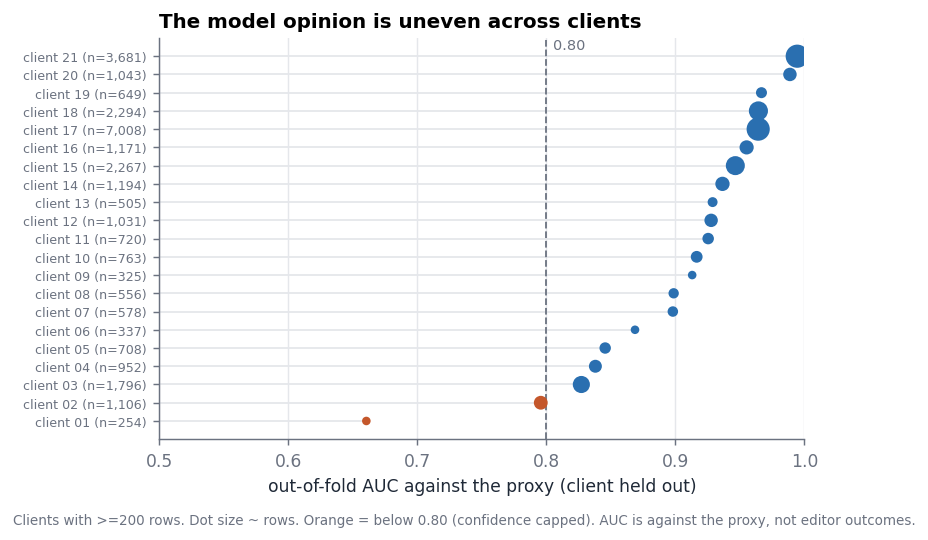

In [10]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
def psi(ref, cur, bins=10):
    ref, cur = np.asarray(ref, float), np.asarray(cur, float)
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3: return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref); c = np.histogram(cur, edges)[0] / len(cur)
    r, c = np.clip(r, 1e-4, None), np.clip(c, 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

KEY = ["ctr", "avg_position", "impressions_last_30d", "days_since_last_update"]
nat = {k: [] for k in KEY}
for tr, te in GroupKFold(n_splits=5).split(X, y, groups):
    for k in KEY: nat[k].append(psi(df.iloc[tr][k], df.iloc[te][k]))
psi_tbl = pd.DataFrame({"max_between_client_fold_PSI": {k: max(v) for k, v in nat.items()},
                        "median_between_client_fold_PSI": {k: float(np.median(v)) for k, v in nat.items()}}).round(3)
psi_tbl["proposed_trigger"] = (psi_tbl["max_between_client_fold_PSI"] * 1.5).clip(lower=0.10).round(2)
USABLE = ["ctr", "avg_position"]        # impressions and update-age differ so much between client groups that a catalogue-level PSI cannot detect drift
print("PSI of a held-out client group vs the rest (5 grouped folds) - the natural spread a new client batch will show:")
print(psi_tbl.to_string())
print("\nProposed trigger = 1.5 x the largest natural between-client PSI (floor 0.10): a new snapshot must look MORE different than a new client does before it counts as drift.")
print(f"Only {USABLE} are usable this way. For impressions_last_30d and days_since_last_update the natural between-client PSI is already huge (clients differ in size and bulk-update dates),")
print("so a catalogue-level PSI would never fire; those two are watched through the queue mix (T5) and per-client medians instead.")

mix = df["action"].value_counts(normalize=True).round(3)
trig = [
 ["T1 Editor acceptance of tier 1", "no decision log yet (not measurable today)", "acceptance of top-50 < 50% over 4 consecutive weekly batches (ASSUMED threshold)", "Review reason codes and thresholds with editors; do not retrain first", "No - build the decision log"],
 ["T2 Did actioned pages improve?", "none (no outcome or comparison data)", "n/a - needs a design: hold ~10% of tier 1-2 back as an untouched comparison group", "This is the only route from decision-support to any 'refresh helps' statement", "No - needs a holdout"],
 ["T3 Input drift on key columns", f"largest between-client-group PSI: {psi_tbl.loc[USABLE, 'max_between_client_fold_PSI'].to_dict()}", f"PSI above {psi_tbl.loc[USABLE, 'proposed_trigger'].to_dict()} on either column for a new snapshot (others watched via T5)", "Re-run notebook + W6 audit; re-check thresholds (0.35 CTR, 90 days, 50 impressions)", "Yes"],
 ["T4 Data quality: missing position", f"{(~pos_ok).mean():.1%} of rows have avg_position = 0", "share above 2x baseline (ASSUMED)", "Fix the export before scoring; data_check queue grows otherwise", "Yes"],
 ["T5 Queue mix shift", f"refresh family {act.mean():.1%} of catalogue; mix {mix.to_dict()}", "any action share moves > 10 percentage points between snapshots (ASSUMED)", "Inspect what changed (data vs real behaviour) before using the new queue", "Yes"],
 ["T6 Model reliability", f"grouped OOF AUC {aucs_A.mean():.3f} (sd {aucs_A.std():.3f}); without ingredient columns {aucs_B.mean():.3f}; {(ca < 0.80).sum()} verified clients < 0.80", "ablated AUC falls by > 0.05, or any 'ok' client becomes 'weak' (ASSUMED)", "Stop using the model opinion for that scope; rely on reason codes", "Yes"],
 ["T7 Scope change", f"{df['client_id'].nunique()} clients, 3 content types, 90-day snapshot", "new content type, new client without GSC history, or a new warehouse release", "Re-run full chain (W4 rule, W5 model, W6 audit) before the queue is used", "Yes"],
 ["T8 Cadence", "snapshot is trailing 90 days", "refresh the snapshot at least monthly; full review quarterly (ASSUMED)", "Re-run this notebook; compare against this run's receipts JSON", "Yes"]]
mon = pd.DataFrame(trig, columns=["trigger", "baseline_today", "fire_when", "then", "measurable_today"])
print("\n" + mon[["trigger", "fire_when", "measurable_today"]].to_string(index=False, max_colwidth=90))
RECEIPTS["monitoring_triggers"] = mon.to_dict(orient="records")
RECEIPTS["psi_between_client_folds"] = psi_tbl.reset_index().rename(columns={"index": "feature"}).to_dict(orient="records")
RECEIPTS["retrain_rule"] = "retrain only after rebuilding the label as past->future; retraining on the current proxy only re-fits the rule"
RECEIPTS["queue_baselines"] = {"actionable_share": round(float(act.mean()), 3), "action_mix": mix.to_dict(), "position_missing_share": round(float((~pos_ok).mean()), 3), "visible_share": round(float(visible.mean()), 3)}

# ---- figure 4: where the model second opinion can be trusted ----
cs = ca.sort_values()
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.hlines(range(len(cs)), 0.5, cs.values, color=GRID, lw=1)
ax.scatter(cs.values, range(len(cs)), s=np.clip(client_n[cs.index].values / 25, 14, 140), color=[C_WARN if v < 0.80 else C_MAIN for v in cs.values], zorder=3)
ax.axvline(0.80, color=MUTED, ls="--", lw=1); ax.text(0.805, len(cs) - 0.6, "0.80", fontsize=8, color=MUTED)
ax.set_yticks(range(len(cs))); ax.set_yticklabels([f"client {i + 1:02d} (n={client_n[c]:,})" for i, c in enumerate(cs.index)], fontsize=7)
ax.set_xlabel("out-of-fold AUC against the proxy (client held out)"); ax.set_xlim(0.5, 1.0); ax.grid(axis="y", visible=False)
ax.set_title("The model opinion is uneven across clients")
fig.text(0.01, -0.02, "Clients with >=200 rows. Dot size ~ rows. Orange = below 0.80 (confidence capped). AUC is against the proxy, not editor outcomes.", fontsize=7.5, color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/w07_fig_client_reliability.png", bbox_inches="tight"); plt.show()


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

| File | Committed? | What it is |
|---|---|---|
| `work/outputs/w07_action_queue.csv` | **No** (CI leak-guard ignores `work/**/*.csv`; this notebook regenerates it) | Full catalogue with action, queue rank (global, per-client, client-balanced), tier, reason codes + text, confidence, review flags |
| `work/outputs/w07_playbook_metrics.json` | **Yes** | Receipts: every headline number, the page-type → action map, decay table, cost/value table, limits, no-go list, monitoring triggers |
| `work/figures/w07_fig_action_mix.png` | **Yes** | Suggested action counts + primary reason in the top of the queue |
| `work/figures/w07_fig_decay_by_freshness.png` | **Yes** | Decline proxy by time since last update |
| `work/figures/w07_fig_value_concentration.png` | **Yes** | Cumulative recoverable-clicks ceiling vs pages reviewed |
| `work/figures/w07_fig_client_reliability.png` | **Yes** | Per-client reliability of the model second opinion |

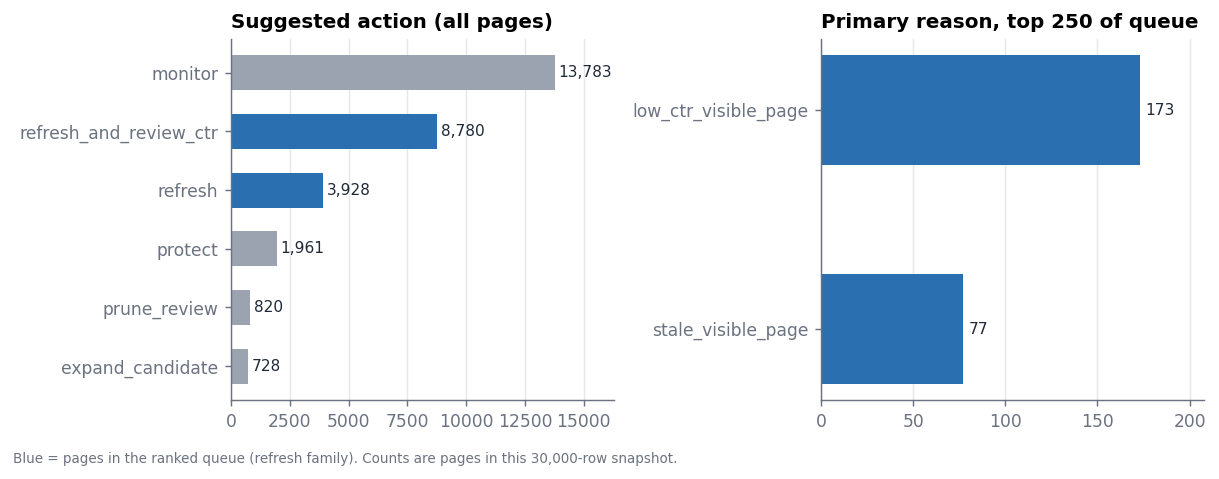

Wrote work/outputs/w07_action_queue.csv: 30,000 rows, 12,708 ranked (1..12,708), 27 columns
Wrote work/outputs/w07_playbook_metrics.json (19 top-level keys)
Figures in work/figures/: ['w07_fig_action_mix.png', 'w07_fig_client_reliability.png', 'w07_fig_decay_by_freshness.png', 'w07_fig_value_concentration.png']

First 5 ranked rows (no IDs shown):
 queue_rank  review_tier                 action       primary_reason confidence  priority_score  model_oof_prob
        1.0 1_review_now                refresh   stale_visible_page     medium         100.000          0.9172
        2.0 1_review_now refresh_and_review_ctr low_ctr_visible_page        low         100.000          0.3857
        3.0 1_review_now refresh_and_review_ctr low_ctr_visible_page        low          99.989          0.4138
        4.0 1_review_now refresh_and_review_ctr low_ctr_visible_page       high          99.977          0.9157
        5.0 1_review_now                refresh   stale_visible_page     medium          9

In [11]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# also an overall action-mix + reason-code figure (the paper's "what the queue looks like" chart)
fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.5), gridspec_kw={"width_ratios": [1, 1]})
am = df["action"].value_counts().sort_values()
axs[0].barh(am.index, am.values, color=[C_MAIN if a in ACTIONABLE else C_ALT for a in am.index], height=0.6)
for i, v in enumerate(am.values): axs[0].text(v + 150, i, f"{v:,}", va="center", fontsize=8.5, color=INK)
axs[0].set_title("Suggested action (all pages)"); axs[0].set_xlim(0, am.max() * 1.18); axs[0].grid(axis="y", visible=False)
t12 = df[df["queue_rank"] <= TIER2]["primary_reason"].value_counts().sort_values()
axs[1].barh(t12.index, t12.values, color=C_MAIN, height=0.5)
for i, v in enumerate(t12.values): axs[1].text(v + 3, i, f"{v}", va="center", fontsize=8.5, color=INK)
axs[1].set_title(f"Primary reason, top {TIER2} of queue"); axs[1].set_xlim(0, t12.max() * 1.2); axs[1].grid(axis="y", visible=False)
fig.text(0.01, -0.03, "Blue = pages in the ranked queue (refresh family). Counts are pages in this 30,000-row snapshot.", fontsize=7.5, color=MUTED)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/w07_fig_action_mix.png", bbox_inches="tight"); plt.show()

# ---------------- the queue file ----------------
df["context_decline_proxy"] = df["is_declining_label"]          # CONTEXT for later evaluation only - never a scoring input
df["proxy_high_label"] = df["y_high"]                           # evaluation only
vis_w4 = visible.astype(int)
df["w4_baseline_score"] = (0.6 * ((pos_ok) & (pos <= 20) & (df["ctr"] < 0.35)).astype(int) * vis_w4 * np.log1p(df["impressions_last_30d"])
                           + 0.4 * (df["days_since_last_update"] >= 90).astype(int) * vis_w4 * np.log1p(df["impressions_last_30d"])).round(3)
cols = ["queue_rank", "review_tier", "client_queue_rank", "client_balanced_rank", "content_id", "client_id", "action", "page_type", "primary_reason", "reason_codes", "reason_text",
        "confidence", "review_flags", "needs_extra_check", "priority_score", "model_oof_prob", "w4_baseline_score",
        "avg_position", "ctr", "impressions_last_30d", "impressions_90d", "days_since_last_update", "content_type",
        "click_gap_90d", "effort_hours_assumed", "context_decline_proxy", "proxy_high_label"]
queue = df.sort_values(["queue_rank", "impressions_last_30d"], ascending=[True, False], na_position="last")[cols].reset_index(drop=True)
for c_ in ["queue_rank", "client_queue_rank", "client_balanced_rank"]: queue[c_] = queue[c_].astype("Int64")
QUEUE_PATH = f"{OUT_DIR}/w07_action_queue.csv"
queue.to_csv(QUEUE_PATH, index=False)

RECEIPTS["exports"] = {"queue_csv": QUEUE_PATH, "queue_rows": int(len(queue)), "ranked_rows": int(queue["queue_rank"].notna().sum()),
                       "tier1": TIER1, "tier2": TIER2, "figures": sorted(os.listdir(FIG_DIR))}
RECEIPTS["queue_columns"] = cols
def clean(o):
    """Strict JSON for the paper: numpy -> python, NaN/inf -> null."""
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if hasattr(o, "item"): o = o.item()
    if isinstance(o, float) and not np.isfinite(o): return None
    return o
with open(f"{OUT_DIR}/w07_playbook_metrics.json", "w") as f:
    json.dump(clean(RECEIPTS), f, indent=2, allow_nan=False)

# ---------------- verify what was written ----------------
chk = pd.read_csv(QUEUE_PATH)
r = chk["queue_rank"].dropna()
assert len(chk) == len(df) == 30000
assert r.is_unique and r.min() == 1 and r.max() == len(r) == int(act.sum()), "queue ranks are not 1..N"
assert chk["content_id"].is_unique
assert chk["client_balanced_rank"].dropna().is_unique and chk["client_balanced_rank"].notna().sum() == len(r)
assert not chk["reason_text"].str.contains("http|www\\.", regex=True).any(), "URL-like text in the queue"
assert set(chk["action"].dropna().unique()) <= set(ACTION_OF.values())
assert chk.loc[chk["queue_rank"].notna(), "action"].isin(ACTIONABLE).all()
loaded = json.load(open(f"{OUT_DIR}/w07_playbook_metrics.json"))
for k in ["model_check", "archetype_action_map", "decay_insight", "cost_value", "limits", "no_go_list", "monitoring_triggers", "exports"]:
    assert k in loaded, f"missing receipts key {k}"
print(f"Wrote {QUEUE_PATH}: {len(chk):,} rows, {len(r):,} ranked (1..{int(r.max()):,}), {chk.shape[1]} columns")
print(f"Wrote {OUT_DIR}/w07_playbook_metrics.json ({len(loaded)} top-level keys)")
print("Figures in work/figures/:", [f for f in sorted(os.listdir(FIG_DIR)) if f.startswith("w07_")])
print("\nFirst 5 ranked rows (no IDs shown):")
print(chk.head(5)[["queue_rank", "review_tier", "action", "primary_reason", "confidence", "priority_score", "model_oof_prob"]].to_string(index=False))
print("\nQueue-file rank check: per-client ranks restart at 1 for every client:", bool(chk.groupby("client_id")["client_queue_rank"].min().dropna().eq(1).all()))

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

In [12]:
# ---- automated self-check: the things a reviewer would grep for ----
import re
risky = ["proves", "will increase", "the algorithm rewards", "predicted google", "guarantee"]
txt = " ".join(chk["reason_text"].astype(str).tolist()).lower()
print("Risky wording in the exported reason text:", {w: len(re.findall(w, txt)) for w in risky})
assert not any(w in txt for w in risky)
print("Banned label columns in the exported queue (should be only the two labelled evaluation-only columns):", [c for c in chk.columns if c in BANNED or "decline" in c or "proxy_high" in c])
print("Queue file present:", os.path.exists(QUEUE_PATH), "| receipts JSON present:", os.path.exists(f"{OUT_DIR}/w07_playbook_metrics.json"))
print("Figures present:", all(os.path.exists(f"{FIG_DIR}/{f}") for f in ["w07_fig_decay_by_freshness.png", "w07_fig_value_concentration.png", "w07_fig_client_reliability.png", "w07_fig_action_mix.png"]))

Risky wording in the exported reason text: {'proves': 0, 'will increase': 0, 'the algorithm rewards': 0, 'predicted google': 0, 'guarantee': 0}
Banned label columns in the exported queue (should be only the two labelled evaluation-only columns): ['context_decline_proxy', 'proxy_high_label']
Queue file present: True | receipts JSON present: True
Figures present: True
